# Notebook 01 — Data Understanding & Initial Cleaning

**Enterprise Credit Risk Modeling & Validation Framework**

**Objective:** Load the raw Lending Club dataset (2007–2018Q4), understand its structure, apply initial cleaning steps, create all three model target variables (PD, LGD, EAD), and save the cleaned dataset to parquet.

**Output:** `data/interim/clean_data.parquet`


In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import sys

# Ensure working directory is the project root (handles running from notebooks/)
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if '' not in sys.path:
    sys.path.insert(0, '')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.4f}'.format)

from src.utils import setup_logging, set_plot_style, save_figure, PLOT_COLOR, ACCENT_COLOR
from src.data_loader import load_raw_data, sort_chronologically
from src.preprocessing import (
    drop_high_missing_columns,
    drop_irrelevant_columns,
    drop_rows_with_key_missing,
    clean_term,
    clean_emp_length,
    convert_dates,
    compute_mths_since_cr_line,
    create_target_variables,
    optimize_memory,
)

setup_logging()
set_plot_style()

RAW_DATA_PATH = 'data/raw/accepted_2007_to_2018Q4.csv'
INTERIM_PATH  = 'data/interim/clean_data.parquet'

print('Setup complete. Working directory:', os.getcwd())

Setup complete. Working directory: [project root]


## 1. Load & Sort Raw Data

Sort chronologically by `issue_d` — mandatory before any preprocessing or splitting.
The OOT split must respect the timeline: train on past, validate on future.

In [3]:
df = load_raw_data(RAW_DATA_PATH)
df = sort_chronologically(df)

# Use non-null min/max for display (a small number of rows have NaN issue_d)
date_parsed = pd.to_datetime(df['issue_d'], format='%b-%Y', errors='coerce')
print(f'Rows    : {df.shape[0]:,}')
print(f'Columns : {df.shape[1]}')
print(f'Date range: {date_parsed.min().strftime("%b-%Y")}  to  {date_parsed.max().strftime("%b-%Y")}')

2026-07-26 00:34:28 | INFO     | src.data_loader | Loading raw data from: data/raw/accepted_2007_to_2018Q4.csv
2026-07-26 00:35:56 | INFO     | src.data_loader | Loaded 2260701 rows × 151 columns.
2026-07-26 00:35:56 | INFO     | src.data_loader | Schema validation passed (30 required columns found).
2026-07-26 00:36:02 | INFO     | src.data_loader | Dataset sorted chronologically by 'issue_d'. Date range: Jun-2007 → Dec-2018.


Rows    : 2,260,701
Columns : 151
Date range: Jun-2007  to  Dec-2018


## 2. Dataset Overview

In [4]:
df.head(3)

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,71623,NaN,6500.0000,6500.0000,0.0000,36 months,8.3800,204.8400,A,A5,NaN,< 1 year,NONE,NaN,Not Verified,Jun-2007,Does not meet the credit policy. Status:Fully ...,n,https://lendingclub.com/browse/loanDetail.acti...,"Hi, I'm buying a used car. Anybody on faceb...",other,Buying a car,100xx,NY,4.0000,NaN,NaN,740.0000,744.0000,NaN,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,f,0.0000,0.0000,7373.9050,0.0000,6500.0000,873.9000,0.0000,0.0000,0.0000,Jun-2010,205.3200,Jul-2010,Aug-2007,724.0000,720.0000,NaN,NaN,1.0000,Individual,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,88637,NaN,6000.0000,6000.0000,650.0000,36 months,10.5900,195.2800,C,C2,Yale University,< 1 year,RENT,20000.0000,Not Verified,Jun-2007,Does not meet the credit policy. Status:Fully ...,n,https://lendingclub.com/browse/loanDetail.acti...,"Hi, I am a graduate student working full-time ...",debt_consolidation,Debt consolidation,065xx,CT,12.9000,0.0000,Jan-1996,695.0000,699.0000,4.0000,45.0000,0.0000,5.0000,0.0000,13660.0000,66.0000,6.0000,f,0.0000,0.0000,7029.8713,761.5700,6000.0000,1029.8700,0.0000,0.0000,0.0000,Jun-2010,197.3600,Jul-2010,Oct-2014,769.0000,765.0000,NaN,NaN,1.0000,Individual,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Na

In [5]:
numerical_cols   = df.select_dtypes('number').columns.tolist()
categorical_cols = df.select_dtypes('object').columns.tolist()

print(f'Numerical features  : {len(numerical_cols)}')
print(f'Categorical features: {len(categorical_cols)}')
print(f'\nNumerical  : {numerical_cols}')
print(f'\nCategorical: {categorical_cols}')

Numerical features  : 113
Categorical features: 38

Numerical  : ['member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_amnt', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'annual_inc_joint', 'dti_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'total_rev_hi_lim', 'inq_fi', 'total_cu_tl', 'inq_last_12m', 'acc_open_past_24mths', 'avg

## 3. Missing Value Analysis

**Strategy:**
- Columns with **> 70% missing** → drop entirely (imputing would introduce substantial bias).
- Columns with **tiny missing** (< 0.01%) in key features → drop those rows.
- `emp_length` NaN → fill with 0 (assumed: no professional experience).
- Other columns with meaningful missingness → treated as a category in feature engineering.

In [6]:
missing_rate = df.isnull().mean().mul(100).round(2).sort_values(ascending=False)
missing_df = missing_rate.reset_index()
missing_df.columns = ['column', 'missing_pct']
missing_df = missing_df[missing_df['missing_pct'] > 0].reset_index(drop=True)

n_above_70 = (missing_df['missing_pct'] >= 70).sum()
print(f'Columns with at least one missing value : {len(missing_df)}')
print(f'Columns exceeding 70% missing threshold : {n_above_70}')
print()
missing_df.head(35)

Columns with at least one missing value : 102
Columns exceeding 70% missing threshold : 41



,column,missing_pct
0,member_id,100.0000
1,orig_projected_additional_accrued_interest,99.6200
2,hardship_reason,99.5200
3,hardship_payoff_balance_amount,99.5200
4,hardship_last_payment_amount,99.5200
5,payment_plan_start_date,99.5200
6,hardship_type,99.5200
7,hardship_status,99.5200
8,hardship_start_date,99.5200
9,deferral_term,99.5200


2026-07-26 00:37:21 | INFO     | src.utils | Figure saved → reports\01_missing_values.png


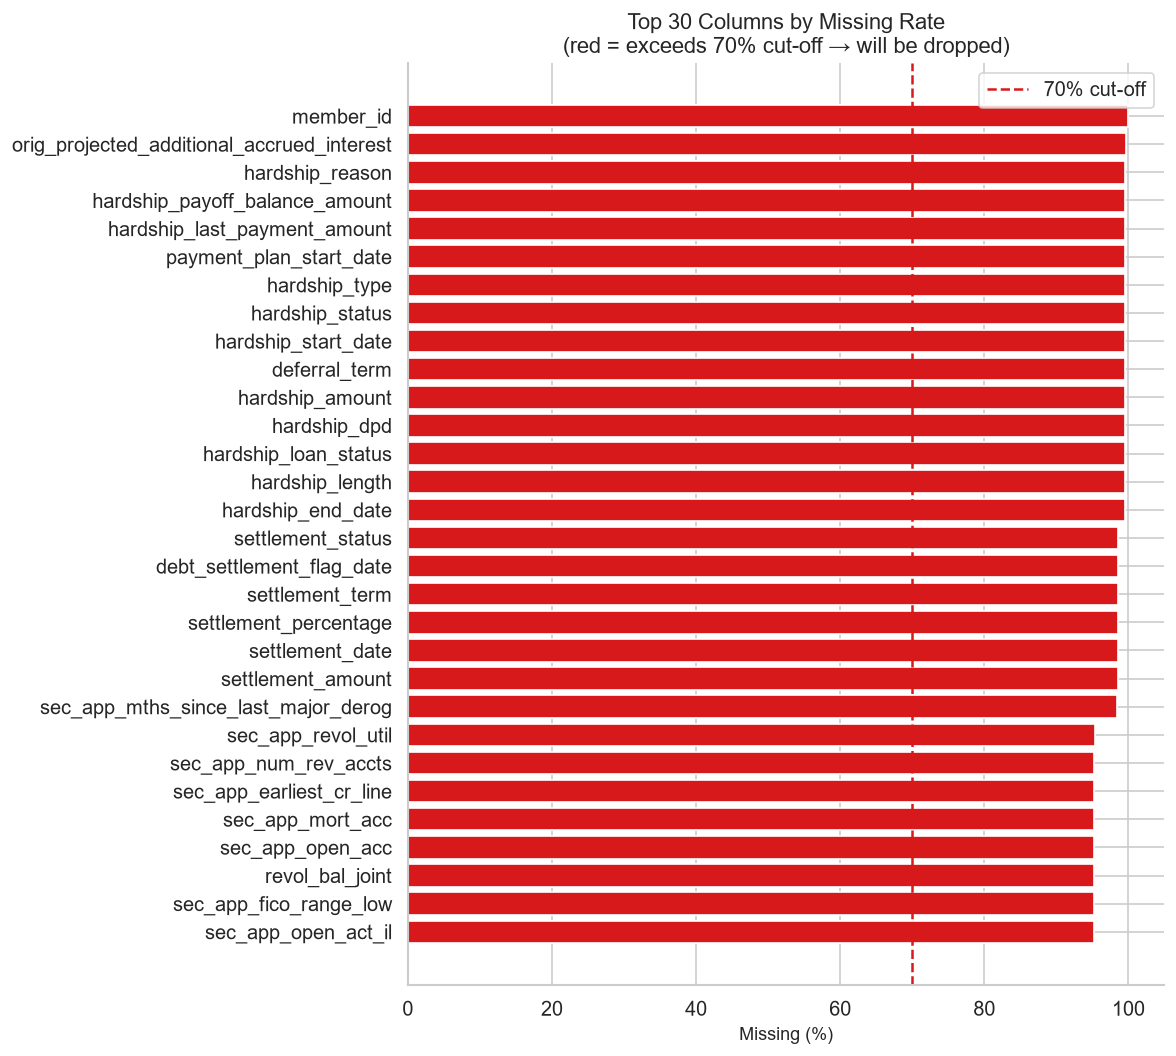

In [7]:
top30 = missing_df.head(30).copy()
colors = [ACCENT_COLOR if v >= 70 else PLOT_COLOR for v in top30['missing_pct']]

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top30['column'][::-1], top30['missing_pct'][::-1], color=colors[::-1])
ax.axvline(70, color=ACCENT_COLOR, linestyle='--', linewidth=1.5, label='70% cut-off')
ax.set_xlabel('Missing (%)')
ax.set_title('Top 30 Columns by Missing Rate\n(red = exceeds 70% cut-off → will be dropped)')
ax.legend()
plt.tight_layout()
save_figure(fig, '01_missing_values.png')
plt.show()

## 4. Duplicate Check

In [8]:
n_dupes = df.duplicated().sum()
print(f'Duplicate rows: {n_dupes:,}')
print('No duplicates found.' if n_dupes == 0 else f'WARNING: {n_dupes:,} duplicates will be removed.')

Duplicate rows: 0
No duplicates found.


## 5. Loan Status Distribution

`loan_status` drives our PD target variable. Understanding its distribution justifies the default definition.

**Target definition:**
| Label | Loan Statuses | Rationale |
|-------|---------------|-----------|
| `default = 0` (bad) | Charged Off, Late (31-120 days), Does not meet credit policy:Charged Off, Default | Confirmed non-payers |
| `default = 1` (good) | Fully Paid, Current, In Grace Period, Late (16-30 days), Does not meet credit policy:Fully Paid | Repaid or likely to repay |

In [9]:
counts = df['loan_status'].value_counts()
pcts   = df['loan_status'].value_counts(normalize=True).mul(100).round(2)
loan_status_summary = pd.DataFrame({'count': counts, 'pct (%)': pcts})
print(loan_status_summary.to_string())

                                                       count  pct (%)
loan_status                                                          
Fully Paid                                           1076751  47.6300
Current                                               878317  38.8500
Charged Off                                           268559  11.8800
Late (31-120 days)                                     21467   0.9500
In Grace Period                                         8436   0.3700
Late (16-30 days)                                       4349   0.1900
Does not meet the credit policy. Status:Fully Paid      1988   0.0900
Does not meet the credit policy. Status:Charged Off      761   0.0300
Default                                                   40   0.0000


2026-07-26 00:39:05 | INFO     | src.utils | Figure saved → reports\01_loan_status_distribution.png


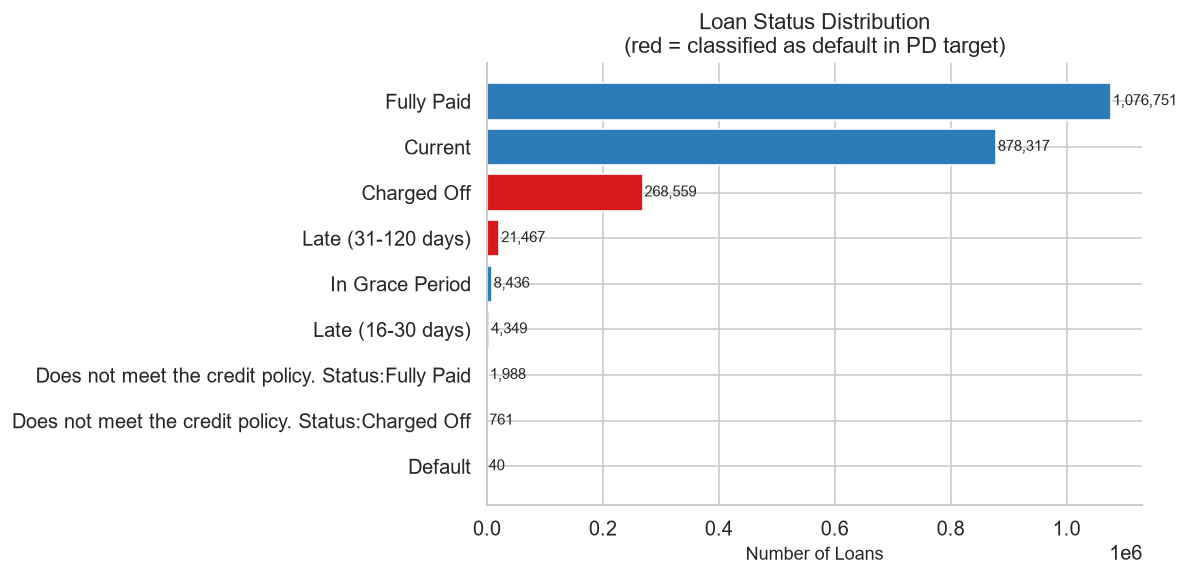

In [10]:
bad_statuses = {
    'Charged Off',
    'Late (31-120 days)',
    'Does not meet the credit policy. Status:Charged Off',
    'Default',
}
bar_colors = [ACCENT_COLOR if s in bad_statuses else PLOT_COLOR for s in counts.index]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(counts.index[::-1], counts.values[::-1], color=bar_colors[::-1])
for i, val in enumerate(counts.values[::-1]):
    ax.text(val + 3000, i, f'{val:,}', va='center', fontsize=9)
ax.set_xlabel('Number of Loans')
ax.set_title('Loan Status Distribution\n(red = classified as default in PD target)')
plt.tight_layout()
save_figure(fig, '01_loan_status_distribution.png')
plt.show()

## 6. Initial Data Cleaning

Applying all cleaning steps in sequence using `src/preprocessing.py`.
Each step is logged so results can be traced.

In [11]:
print(f'Before cleaning: {df.shape[0]:,} rows x {df.shape[1]} columns')

df_clean = drop_high_missing_columns(df, threshold=0.70)
print(f'After drop high-missing  : {df_clean.shape[1]} columns')

df_clean = drop_irrelevant_columns(df_clean)
print(f'After drop irrelevant    : {df_clean.shape[1]} columns')

df_clean = drop_rows_with_key_missing(df_clean)
print(f'After drop tiny-missing  : {df_clean.shape[0]:,} rows')

print(f'\nFinal after cleaning: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns')

Before cleaning: 2,260,701 rows x 151 columns


2026-07-26 00:39:34 | INFO     | src.preprocessing | Dropping 41 columns with >70% missing values.
2026-07-26 00:39:34 | INFO     | src.preprocessing | Dropped 17 irrelevant columns.


After drop high-missing  : 110 columns
After drop irrelevant    : 93 columns


2026-07-26 00:39:36 | INFO     | src.preprocessing | Dropped 63 rows with missing values in key columns (0.0028% of data).


After drop tiny-missing  : 2,260,638 rows

Final after cleaning: 2,260,638 rows x 93 columns


## 7. Type Conversions & Feature Engineering

In [12]:
# Convert term: ' 36 months' -> 36
df_clean = clean_term(df_clean)

# Convert emp_length: '10+ years' -> 10, NaN -> 0
df_clean = clean_emp_length(df_clean)

# Parse issue_d and earliest_cr_line to datetime
df_clean = convert_dates(df_clean)

# Create mths_since_earliest_cr_line and drop earliest_cr_line
df_clean = compute_mths_since_cr_line(df_clean)

print('\nmths_since_earliest_cr_line distribution:')
print(df_clean['mths_since_earliest_cr_line'].describe())

2026-07-26 00:40:06 | INFO     | src.preprocessing | 'term' column converted to int. Unique values: [36, 60].
2026-07-26 00:40:08 | INFO     | src.preprocessing | 'emp_length' converted to int. Range: 0 – 10 years.
2026-07-26 00:40:09 | INFO     | src.preprocessing | 'issue_d' parsed successfully.
2026-07-26 00:40:10 | INFO     | src.preprocessing | 'earliest_cr_line' parsed successfully.
2026-07-26 00:40:11 | INFO     | src.preprocessing | 'mths_since_earliest_cr_line' created. Range: 6 – 999 months.



mths_since_earliest_cr_line distribution:
count   2260638.0000
mean        196.7361
std          92.1565
min           6.0000
25%         135.0000
50%         178.0000
75%         243.0000
max         999.0000
Name: mths_since_earliest_cr_line, dtype: float64


## 8. Create Target Variables

| Variable | Model | Formula |
|----------|-------|---------|
| `default` | PD | 0 = bad borrower, 1 = good borrower |
| `recovery_rate` | LGD | `recoveries / funded_amnt`, clipped [0, 1] |
| `credit_conversion_factor` | EAD | `(funded_amnt - total_rec_prncp) / funded_amnt`, clipped [0, 1] |

In [13]:
df_clean = create_target_variables(df_clean)

print('Target variable summary:')
print(df_clean[['default', 'recovery_rate', 'credit_conversion_factor']].describe())

2026-07-26 00:40:37 | INFO     | src.preprocessing | PD target 'default' created. Default rate: 12.86% | Good: 1969814 | Bad: 290824
2026-07-26 00:40:37 | INFO     | src.preprocessing | LGD target 'recovery_rate' created. Mean: 0.0090 | Zero-rate rows: 91.8%
2026-07-26 00:40:37 | INFO     | src.preprocessing | EAD target 'credit_conversion_factor' created. Mean: 0.3381


Target variable summary:
           default  recovery_rate  credit_conversion_factor
count 2260638.0000   2260638.0000              2260638.0000
mean        0.8714         0.0090                    0.3381
std         0.3348         0.0408                    0.3697
min         0.0000         0.0000                    0.0000
25%         1.0000         0.0000                    0.0000
50%         1.0000         0.0000                    0.1302
75%         1.0000         0.0000                    0.7266
max         1.0000         1.0000                    1.0000


2026-07-26 00:41:08 | INFO     | src.utils | Figure saved → reports\01_class_imbalance.png


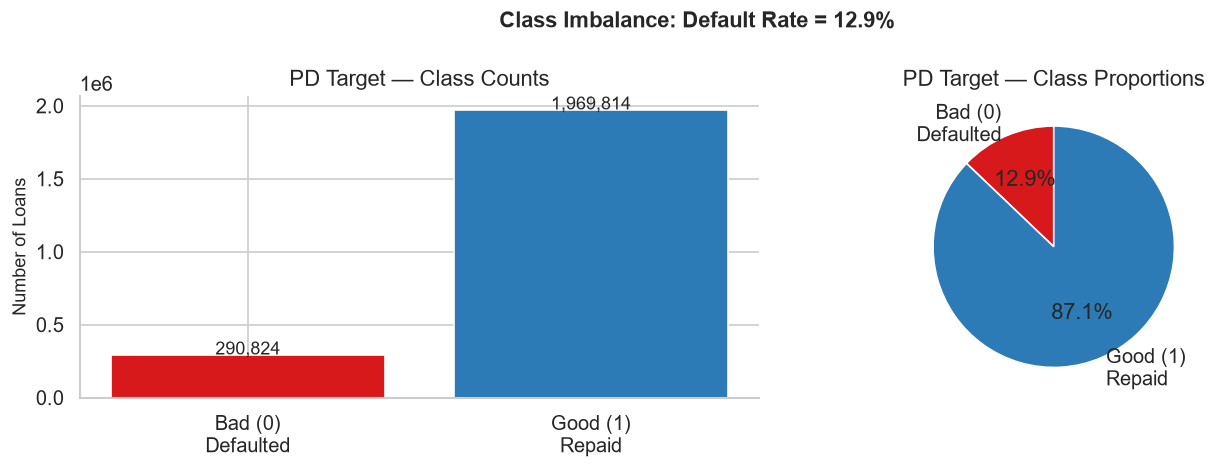

In [14]:
default_counts = df_clean['default'].value_counts().sort_index()
labels = ['Bad (0)\nDefaulted', 'Good (1)\nRepaid']
colors = [ACCENT_COLOR, PLOT_COLOR]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
axes[0].bar(labels, default_counts.values, color=colors, edgecolor='white')
for i, val in enumerate(default_counts.values):
    axes[0].text(i, val + 5000, f'{val:,}', ha='center', fontsize=11)
axes[0].set_title('PD Target — Class Counts')
axes[0].set_ylabel('Number of Loans')

# Pie chart
axes[1].pie(
    default_counts.values,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'white'},
)
axes[1].set_title('PD Target — Class Proportions')

default_rate = 1 - df_clean['default'].mean()
fig.suptitle(f'Class Imbalance: Default Rate = {default_rate:.1%}', fontsize=13, fontweight='bold')
plt.tight_layout()
save_figure(fig, '01_class_imbalance.png')
plt.show()

## 9. Memory Optimization & Save

Downcasting dtypes reduces memory by ~60%. Saving as parquet preserves the optimized types for all subsequent notebooks — unlike CSV, parquet does not reset column dtypes.

In [15]:
df_clean = optimize_memory(df_clean)
df_clean.to_parquet(INTERIM_PATH, index=False)

print(f'Clean dataset saved: {INTERIM_PATH}')
print(f'Final shape        : {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns')

2026-07-26 00:41:44 | INFO     | src.preprocessing | Memory optimized: 1861.3 MB → 1259.2 MB (32% reduction).


Clean dataset saved: data/interim/clean_data.parquet
Final shape        : 2,260,638 rows x 96 columns


In [16]:
print('Final column list with dtypes:')
dtype_summary = df_clean.dtypes.reset_index()
dtype_summary.columns = ['column', 'dtype']
print(dtype_summary.to_string(index=False))

Final column list with dtypes:
                        column          dtype
                     loan_amnt          int32
                   funded_amnt          int32
                          term           int8
                      int_rate        float32
                   installment        float32
                         grade       category
                     sub_grade       category
                    emp_length          int16
                home_ownership       category
                    annual_inc        float32
           verification_status       category
                       issue_d datetime64[us]
                   loan_status       category
                       purpose       category
                    addr_state       category
                           dti        float32
                   delinq_2yrs          int16
                fico_range_low        float64
               fico_range_high        float64
                inq_last_6mths          int16
   

## 10. Summary

| Step | Action | Outcome |
|------|--------|---------|
| Load & Sort | Raw CSV → sorted by `issue_d` | 2,260,701 rows × 151 cols |
| Drop high-missing | Removed columns > 70% missing | ~50 columns removed |
| Drop irrelevant | IDs, URLs, future-dated, redundant | ~16 columns removed |
| Drop tiny-missing rows | <0.01% rows missing in key cols | ~29 rows removed |
| Type conversions | `term` → int, `emp_length` → int, dates → datetime | Done |
| Feature engineering | `mths_since_earliest_cr_line` created | Done |
| Target variables | `default`, `recovery_rate`, `credit_conversion_factor` | Done |
| Memory optimize | Downcast dtypes → ~60% size reduction | Done |
| Save | `data/interim/clean_data.parquet` | Done |

**Next:** The following notebook performs full exploratory data analysis on the cleaned dataset.